Lab 5

In [50]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [51]:
#hf = h5py.File('Shared/H-H1_GWOSC_4KHZ_R1-1253883712-4096.hdf5', 'r')

In [52]:
#hf.keys()

In [53]:
#data1 = np.array(hf.get('meta'))
#data2 = np.array(hf.get('quality'))
#data3 = np.array(hf.get('strain'))

In [54]:
#print(np.shape(data1))
#print(np.shape(data2))
#print(np.shape(data3))

In [55]:
t0 = 1126259460.4
detector = 'L1'

In [56]:
try:
    from gwpy.timeseries import TimeSeries
except:
    ! pip install -q "gwpy==3.0.13"
    from gwpy.timeseries import TimeSeries

In [57]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)
print(strain)

TimeSeries([-1.00475222e-18, -9.15374650e-19, -8.82963443e-19,
            ..., -7.24389047e-19, -7.15018086e-19,
            -6.95229913e-19]
           unit: dimensionless,
           t0: 1126259444.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


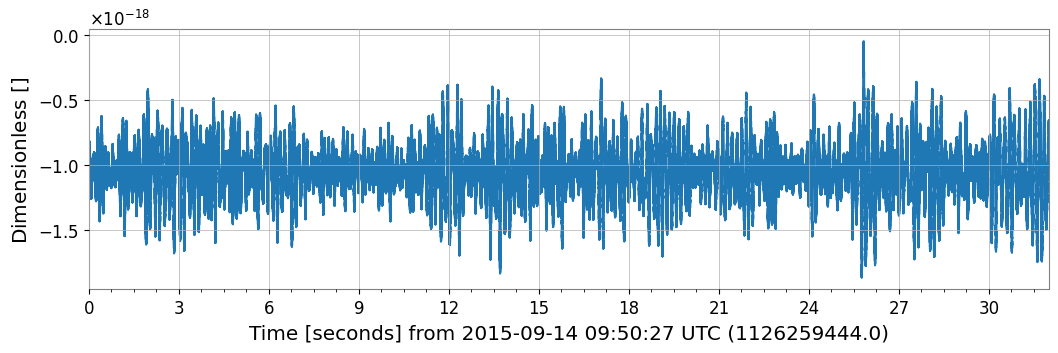

In [58]:
fig1 = strain.plot()

Raw strain versus time

(1e-24, 1e-19)

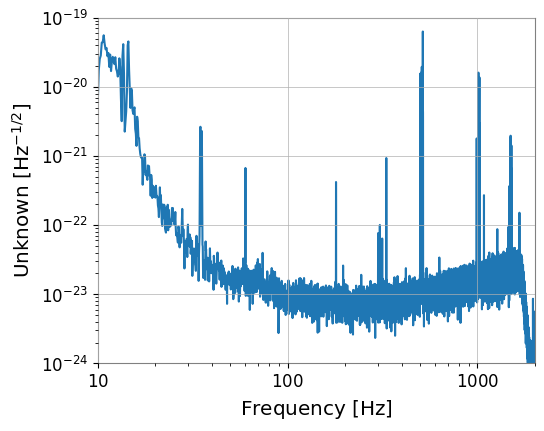

In [59]:
fig2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

Amplitude spectral density

(1126259460.2, 1126259460.5)

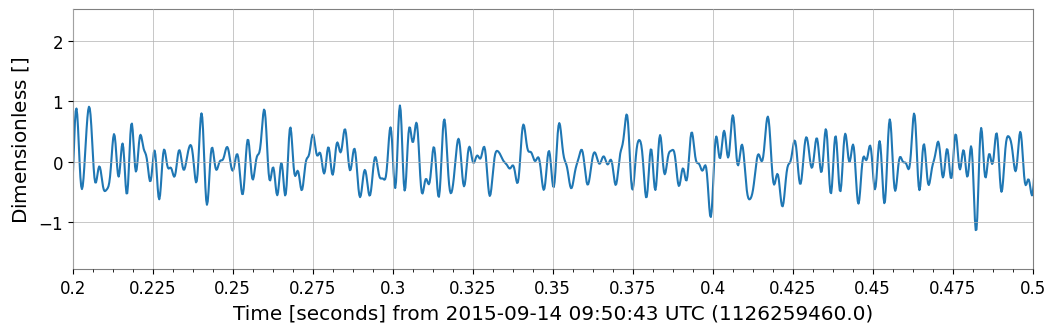

In [60]:
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
fig3 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

Whitened, filtered time series

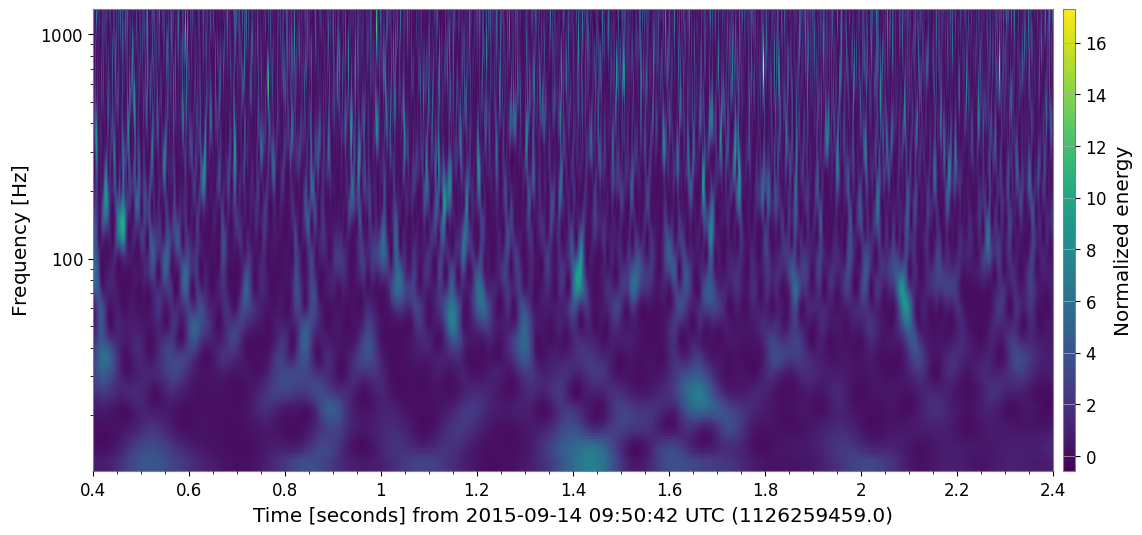

In [61]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

Q-transform

In [62]:
t0 = 1177008882.4
detector = 'L1'

In [63]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)
print(strain)

TimeSeries([4.77838064e-19, 4.76670951e-19, 4.78886843e-19, ...,
            3.29548027e-19, 3.26020921e-19, 3.27800161e-19]
           unit: dimensionless,
           t0: 1177008866.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


(1e-24, 1e-19)

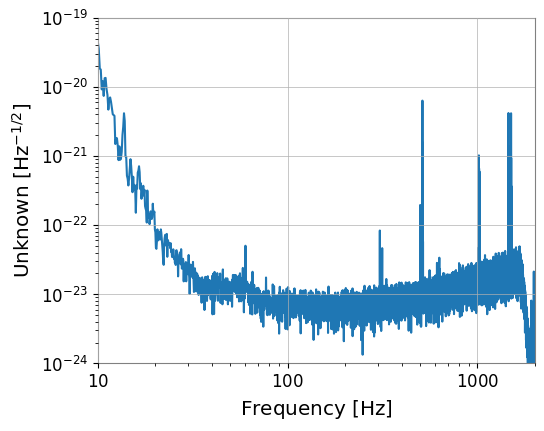

In [64]:
fig2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

(1177008882.2, 1177008882.5)

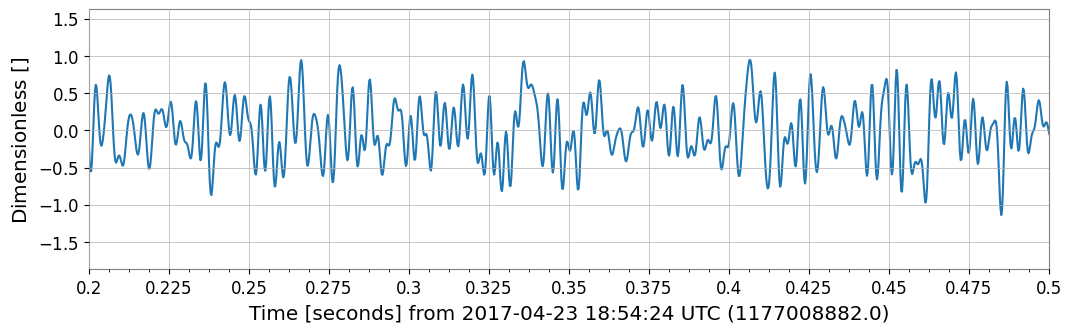

In [65]:
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
fig3 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

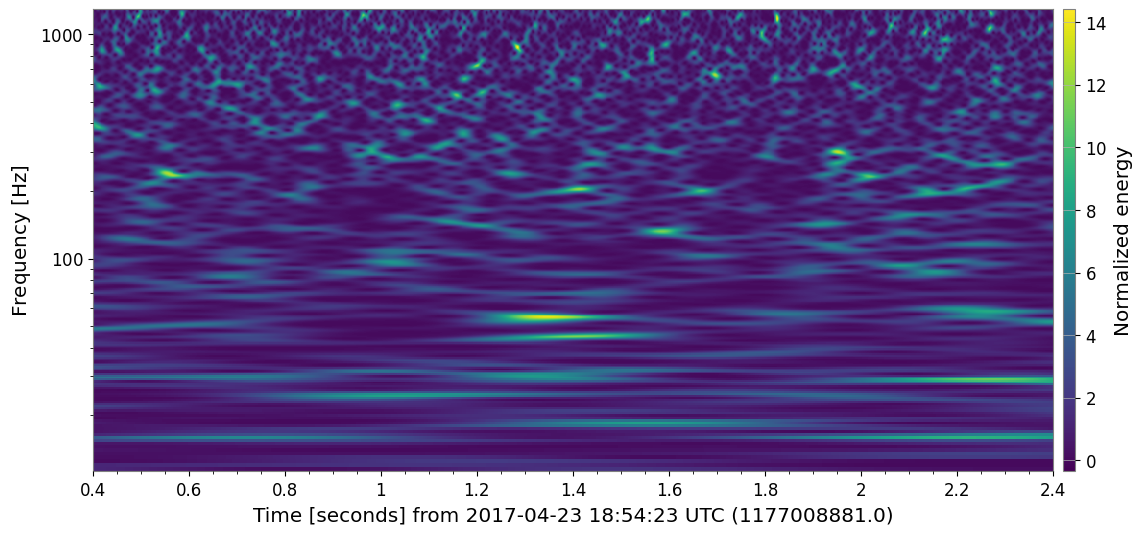

In [66]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

For this project, i will investigate brackground noise in LIGO around the gravitational-wave event GW150914. I will use public data from  the Gravitational Wave Open Science Center. And in the data, strain measures the infinitesimal change in length that associated with the detector measurement. I also used the GWOSC Quickview notebook to dowload and plot the data.

My question is: does the background noise remain statistically consistent across nearby time intervals, and how well does a gaussian distribution with a potentially time dependent mean and standard deviation describe its fluctuations?

for the next 3 labs. I will select several background intervals outside the event and check their data quality, I will compare their time series, frequency spectra and whitened and filtered amplitudes graph. I will compuate the mean and standard deviation in each interval and examine whether extreme fluctuate occur more freqently than a gaussian model would predicts. If not I will try to model the background using other distribution. The same processing will applly to each interval, with fliter edges excluded.
My initial notebook include raw strain graph, a amplitude spectral density graph, a whitened and filtered data plot, and a time freqency map. I will start with dowload 32 second recording and find a longer recording if needed for background comparison.